# DATASET BILLETS


In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
df_billets = pd.read_csv('../data/raw/Dome_billets.csv')
print(df_billets.columns.to_list())

df_billets.head()

['billet_id', 'evenement_id', 'zone', 'prix_paye_eur', 'achat_jours_avant', 'arrivee_min_avant', 'x_salle_m', 'y_salle_m', 'conso_bar_eur', 'age', 'deja_venu', 'revient_saison_suivante']


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante
0,BL600680,EV369,loge,73.66,53.0,23.0,16.6,-13.5,28.63,41.0,non,oui
1,BL600471,EV386,fosse,122.64,44.0,56.0,0.7,-1.7,10.63,44.0,non,non
2,BL600421,EV313,gradin bas,59.81,29.0,34.0,-10.3,-21.7,3.01,32.0,non,non
3,BL600643,EV342,gradin bas,86.22,33.0,32.0,12.9,21.4,4.71,42.0,non,non
4,BL600447,EV388,gradin haut,67.45,102.0,81.0,-35.3,42.9,NaN,30.0,oui,oui


In [3]:
# Informations générales sur le dataset

print("Shape")
print(df_billets.shape)

print("\n types des colonnes")
print(df_billets.dtypes)

print("\n Valeurs manquantes")
print(df_billets.isnull().sum().sort_values(ascending=False))

print("\n Stats descriptives")
df_billets.describe()


Shape
(820, 12)

 types des colonnes
billet_id                      str
evenement_id                   str
zone                           str
prix_paye_eur              float64
achat_jours_avant          float64
arrivee_min_avant          float64
x_salle_m                  float64
y_salle_m                  float64
conso_bar_eur              float64
age                        float64
deja_venu                      str
revient_saison_suivante        str
dtype: object

 Valeurs manquantes
age                        19
conso_bar_eur              16
billet_id                   0
evenement_id                0
prix_paye_eur               0
zone                        0
achat_jours_avant           0
arrivee_min_avant           0
y_salle_m                   0
x_salle_m                   0
deja_venu                   0
revient_saison_suivante     0
dtype: int64

 Stats descriptives


,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age
count,820.000000,820.000000,820.000000,820.000000,820.000000,804.000000,801.000000
mean,70.104598,42.100000,39.703659,0.491341,0.671707,7.224179,34.314607
std,30.338363,30.410657,23.115070,25.434452,25.012094,7.028390,12.734438
min,0.000000,0.000000,-20.000000,-60.100000,-58.900000,0.000000,12.000000
25%,47.900000,19.000000,23.000000,-15.700000,-16.700000,2.575000,25.000000
50%,69.575000,35.000000,39.000000,0.200000,0.150000,5.955000,34.000000
75%,91.200000,56.000000,56.000000,17.075000,17.350000,9.397500,43.000000
max,174.130000,187.000000,121.000000,61.800000,61.300000,35.760000,82.000000


## 1. Etude des doublons

In [4]:
print("Etude de potentiels doublons sur le dataset")

print("\n Doublons - lignes entières")
print(df_billets.duplicated().sum())

print("\n Lignes concernées")
display(df_billets[df_billets.duplicated(keep=False)].sort_values(by='billet_id'))

print("\n ====================================================================================================================================")


print("\n Doublons - même billet_id")
print(df_billets.duplicated(subset='billet_id').sum())

print("\n Lignes concernées")
display(df_billets[df_billets.duplicated(subset='billet_id', keep=False)].sort_values(by='billet_id'))

print("\n ====================================================================================================================================")



colonnes_sans_id = df_billets.columns.drop('billet_id')

print("\n Doublons - même contenu, id différent")
print(df_billets.duplicated(subset=colonnes_sans_id).sum())

print("\n Lignes concernées")
display(df_billets[df_billets.duplicated(subset=colonnes_sans_id, keep=False)].sort_values(by=['evenement_id', 'billet_id']))

Etude de potentiels doublons sur le dataset

 Doublons - lignes entières
120

 Lignes concernées


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante
429,BL600000,EV354,fosse,95.61,18.0,59.0,-11.5,6.6,8.60,42.0,oui,non
432,BL600000,EV354,fosse,95.61,18.0,59.0,-11.5,6.6,8.60,42.0,oui,non
804,BL600008,EV367,gradin haut,89.70,37.0,40.0,41.3,-22.8,0.00,35.0,non,non
626,BL600008,EV367,gradin haut,89.70,37.0,40.0,41.3,-22.8,0.00,35.0,non,non
616,BL600013,EV300,fosse,55.38,7.0,39.0,-12.9,10.5,0.90,42.0,non,oui
...,...,...,...,...,...,...,...,...,...,...,...,...
151,BL600683,EV326,gradin bas,89.88,81.0,64.0,0.9,-27.9,15.06,48.0,oui,non
355,BL600684,EV351,gradin bas,46.59,28.0,47.0,-4.0,26.8,0.89,47.0,non,non
203,BL600684,EV351,gradin bas,46.59,28.0,47.0,-4.0,26.8,0.89,47.0,non,non
273,BL600697,EV385,gradin bas,97.58,44.0,59.0,-23.2,-10.4,8.01,12.0,non,oui




 Doublons - même billet_id
120

 Lignes concernées


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante
429,BL600000,EV354,fosse,95.61,18.0,59.0,-11.5,6.6,8.60,42.0,oui,non
432,BL600000,EV354,fosse,95.61,18.0,59.0,-11.5,6.6,8.60,42.0,oui,non
804,BL600008,EV367,gradin haut,89.70,37.0,40.0,41.3,-22.8,0.00,35.0,non,non
626,BL600008,EV367,gradin haut,89.70,37.0,40.0,41.3,-22.8,0.00,35.0,non,non
616,BL600013,EV300,fosse,55.38,7.0,39.0,-12.9,10.5,0.90,42.0,non,oui
...,...,...,...,...,...,...,...,...,...,...,...,...
151,BL600683,EV326,gradin bas,89.88,81.0,64.0,0.9,-27.9,15.06,48.0,oui,non
355,BL600684,EV351,gradin bas,46.59,28.0,47.0,-4.0,26.8,0.89,47.0,non,non
203,BL600684,EV351,gradin bas,46.59,28.0,47.0,-4.0,26.8,0.89,47.0,non,non
273,BL600697,EV385,gradin bas,97.58,44.0,59.0,-23.2,-10.4,8.01,12.0,non,oui




 Doublons - même contenu, id différent
120

 Lignes concernées


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante
57,BL600013,EV300,fosse,55.38,7.0,39.0,-12.9,10.5,0.90,42.0,non,oui
616,BL600013,EV300,fosse,55.38,7.0,39.0,-12.9,10.5,0.90,42.0,non,oui
527,BL600311,EV300,gradin bas,83.94,50.0,31.0,5.7,-24.8,3.12,18.0,oui,oui
569,BL600311,EV300,gradin bas,83.94,50.0,31.0,5.7,-24.8,3.12,18.0,oui,oui
141,BL600581,EV300,loge,80.26,17.0,38.0,16.8,-12.9,27.26,46.0,non,oui
...,...,...,...,...,...,...,...,...,...,...,...,...
667,BL600517,EV391,gradin haut,62.94,113.0,23.0,39.5,41.6,5.98,13.0,non,oui
320,BL600111,EV392,gradin bas,79.71,47.0,16.0,-16.4,27.4,9.17,23.0,oui,oui
500,BL600111,EV392,gradin bas,79.71,47.0,16.0,-16.4,27.4,9.17,23.0,oui,oui
156,BL600511,EV394,gradin bas,83.67,72.0,43.0,-6.1,32.3,6.07,43.0,oui,oui


120 billets sur 820 (≈ 15 %) sont présents en double à l'identique, chacun exactement deux fois. Aucun `billet_id` n'est en conflit et aucun billet n'est saisi sous deux identifiants. Décision : supprimer les 120 copies lors du preprocessing (820 → 700 billets), pour ne pas fausser les statistiques ni surestimer les performances des modèles (une copie en entraînement, l'autre en test).

## 2. Variables Catégorielles

In [5]:
print("Modalités de la colonne zone")
print("Nombre de modalités :", df_billets['zone'].nunique(dropna=False))
display(df_billets['zone'].value_counts(dropna=False))

Modalités de la colonne zone
Nombre de modalités : 4


zone
gradin bas     288
gradin haut    252
fosse          224
loge            56
Name: count, dtype: int64

In [6]:
print("Modalités de la colonne deja_venu")
print("Nombre de modalités :", df_billets['deja_venu'].nunique(dropna=False))
display(df_billets['deja_venu'].value_counts(dropna=False))

Modalités de la colonne deja_venu
Nombre de modalités : 2


deja_venu
non    476
oui    344
Name: count, dtype: int64

In [7]:
print("Modalités de la colonne revient_saison_suivante")
print("Nombre de modalités :", df_billets['revient_saison_suivante'].nunique(dropna=False))
display(df_billets['revient_saison_suivante'].value_counts(dropna=False))

Modalités de la colonne revient_saison_suivante
Nombre de modalités : 2


revient_saison_suivante
oui    480
non    340
Name: count, dtype: int64

Les trois colonnes catégorielles sont propres : aucune valeur manquante, aucune écriture incohérente (effectifs calculés sur 820 lignes, doublons inclus). `zone` compte 4 modalités, dont la loge avec seulement 56 billets (≈ 7 %). 42 % des spectateurs sont déjà venus et 59 % reviennent la saison suivante. `revient_saison_suivante` est une information postérieure à l'achat : elle ne sera pas utilisée comme variable explicative pour prédire la consommation au bar à l'achat (Q5), pour éviter une fuite de données.

## 3. Valeurs Manquantes

In [8]:
masque_age_nan = df_billets['age'].isnull()

print("Âges manquants :", masque_age_nan.sum(), "sur", len(df_billets))
print(" dont lignes en double :", (masque_age_nan & df_billets.duplicated(keep=False)).sum())

print("\n Répartition par zone (âge manquant)")
display(df_billets.loc[masque_age_nan, 'zone'].value_counts())

display(df_billets[masque_age_nan])

Âges manquants : 19 sur 820
 dont lignes en double : 10

 Répartition par zone (âge manquant)


zone
fosse          7
gradin haut    6
loge           4
gradin bas     2
Name: count, dtype: int64

,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante
22,BL600205,EV359,fosse,54.50,54.0,51.0,-0.2,0.1,3.01,NaN,oui,non
27,BL600608,EV381,gradin haut,71.68,88.0,17.0,20.1,-54.0,0.00,NaN,non,non
74,BL600140,EV359,fosse,28.27,25.0,53.0,5.4,-4.7,7.67,NaN,oui,oui
78,BL600048,EV351,gradin haut,86.66,67.0,48.0,-46.1,-25.6,3.58,NaN,non,oui
94,BL600057,EV334,fosse,76.40,25.0,38.0,-4.9,4.7,6.25,NaN,oui,oui
152,BL600626,EV358,loge,22.60,29.0,63.0,-11.0,20.4,33.10,NaN,non,non
222,BL600626,EV358,loge,22.60,29.0,63.0,-11.0,20.4,33.10,NaN,non,non
229,BL600399,EV365,fosse,53.25,43.0,100.0,0.9,0.0,13.68,NaN,non,non
235,BL600453,EV385,gradin bas,103.88,35.0,43.0,35.8,-8.6,0.00,NaN,oui,oui
251,BL600097,EV374,gradin bas,85.84,47.0,4.0,28.3,-22.9,0.55,NaN,non,non


In [9]:
masque_conso_nan = df_billets['conso_bar_eur'].isnull()
masque_conso_zero = df_billets['conso_bar_eur'] == 0

print("Consommation manquante (NaN) :", masque_conso_nan.sum())
print(" dont lignes en double       :", (masque_conso_nan & df_billets.duplicated(keep=False)).sum())
print("Consommation à 0 €           :", masque_conso_zero.sum())
print("Consommation > 0 €           :", (df_billets['conso_bar_eur'] > 0).sum())

display(df_billets[masque_conso_nan])

Consommation manquante (NaN) : 16
 dont lignes en double       : 4
Consommation à 0 €           : 83
Consommation > 0 €           : 721


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante
4,BL600447,EV388,gradin haut,67.45,102.0,81.0,-35.3,42.9,NaN,30.0,oui,oui
29,BL600605,EV378,gradin haut,88.21,60.0,21.0,46.3,13.7,NaN,12.0,non,non
68,BL600447,EV388,gradin haut,67.45,102.0,81.0,-35.3,42.9,NaN,30.0,oui,oui
72,BL600372,EV334,gradin haut,92.79,60.0,67.0,53.1,-12.6,NaN,32.0,non,non
117,BL600653,EV326,fosse,102.17,38.0,43.0,15.8,2.8,NaN,34.0,oui,oui
216,BL600664,EV325,gradin haut,45.32,46.0,-7.0,-39.7,36.6,NaN,57.0,non,oui
244,BL600409,EV373,gradin haut,67.77,72.0,-0.0,-41.7,-34.6,NaN,36.0,non,non
453,BL600605,EV378,gradin haut,88.21,60.0,21.0,46.3,13.7,NaN,12.0,non,non
538,BL600342,EV345,gradin bas,63.12,85.0,48.0,-32.6,-0.8,NaN,35.0,non,oui
606,BL600548,EV367,fosse,64.57,13.0,39.0,-13.1,-1.7,NaN,35.0,non,oui


In [10]:
groupe_conso = pd.Series('> 0 €', index=df_billets.index)
groupe_conso[masque_conso_zero] = '0 €'
groupe_conso[masque_conso_nan] = 'NaN'

profil = df_billets.groupby(groupe_conso).agg(
    nb_billets=('billet_id', 'count'),
    age_moyen=('age', 'mean'),
    prix_moyen=('prix_paye_eur', 'mean'),
    arrivee_moyenne_min=('arrivee_min_avant', 'mean'),
    part_deja_venu=('deja_venu', lambda s: (s == 'oui').mean())
).round(2)

print("Profil des spectateurs selon leur consommation au bar")
display(profil)

Profil des spectateurs selon leur consommation au bar


,nb_billets,age_moyen,prix_moyen,arrivee_moyenne_min,part_deja_venu
0 €,83,35.24,67.89,31.59,0.46
> 0 €,721,34.21,70.36,40.68,0.42
NaN,16,34.56,70.03,37.94,0.25


In [11]:
masque_deux_nan = masque_age_nan & masque_conso_nan
print("Billets sans âge ET sans consommation :", masque_deux_nan.sum())
display(df_billets[masque_deux_nan])


Billets sans âge ET sans consommation : 0


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante


**Âge :** 19 valeurs manquantes (dont 10 lignes en double, soit 14 billets uniques après nettoyage), réparties dans toutes les zones. Décision : imputation par la médiane au preprocessing, avec un indicateur `age_inconnu` pour conserver ces billets dans les analyses de profil sans masquer qu'ils sont imputés (les âges de 12 ans, traités à l'étape 4, suivront la même règle).

**Consommation au bar :** 16 valeurs manquantes (14 billets uniques après nettoyage), à distinguer des 83 billets à 0 €. Le profil des `NaN` (prix 70 €, arrivée 38 min avant) ressemble à celui des consommateurs (70 €, 41 min) plus qu'à celui des non-consommateurs (68 €, 32 min) : un `NaN` n'est pas un 0. Décision : ne pas imputer ; ces billets sont exclus de la modélisation de la consommation (Q5), dont `conso_bar_eur` est la cible, et conservés pour les autres analyses.

Aucun billet n'a à la fois l'âge et la consommation manquants : les deux problèmes sont indépendants.

## 4. Valeurs suspectes ou impossibles

In [12]:
masque_prix_zero = df_billets['prix_paye_eur'] == 0

print("Billets à 0 € :", masque_prix_zero.sum(), "sur", len(df_billets))
print(" dont lignes en double :", (masque_prix_zero & df_billets.duplicated(keep=False)).sum())

print("\n Répartition par zone")
display(df_billets.loc[masque_prix_zero, 'zone'].value_counts())

print("\n Billets les moins chers (hors 0 €)")
display(df_billets.loc[~masque_prix_zero, 'prix_paye_eur'].sort_values().head(10))

display(df_billets[masque_prix_zero])

Billets à 0 € : 4 sur 820
 dont lignes en double : 2

 Répartition par zone


zone
fosse          3
gradin haut    1
Name: count, dtype: int64


 Billets les moins chers (hors 0 €)


48     12.0
794    12.0
724    12.0
520    12.0
504    12.0
474    12.0
603    12.0
581    12.0
422    12.0
441    12.0
Name: prix_paye_eur, dtype: float64

,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante
6,BL600019,EV305,fosse,0.0,37.0,38.0,-1.7,-10.4,12.38,31.0,non,oui
336,BL600038,EV379,gradin haut,0.0,27.0,44.0,-57.0,9.0,0.00,59.0,oui,oui
382,BL600145,EV388,fosse,0.0,19.0,51.0,-13.9,5.6,4.09,34.0,oui,non
751,BL600019,EV305,fosse,0.0,37.0,38.0,-1.7,-10.4,12.38,31.0,non,oui


4 billets sont à 0 € (3 billets uniques, BL600019 étant en double), isolés du prix minimal suivant (12 €) : il s'agit probablement d'invitations. Décision : conservés, mais exclus des analyses de prix.

In [13]:
masque_retard = df_billets['arrivee_min_avant'] < 0

print("Arrivées après le début (valeur < 0) :", masque_retard.sum(), "sur", len(df_billets))
print(" dont lignes en double :", (masque_retard & df_billets.duplicated(keep=False)).sum())

print("\n Valeurs négatives rencontrées")
display(df_billets.loc[masque_retard, 'arrivee_min_avant'].value_counts().sort_index())

print("\n Valeurs '-0.0' (zéro négatif)")
print((df_billets['arrivee_min_avant'].astype(str) == '-0.0').sum())

display(df_billets[masque_retard])

Arrivées après le début (valeur < 0) : 33 sur 820
 dont lignes en double : 6

 Valeurs négatives rencontrées


arrivee_min_avant
-20.0    4
-18.0    1
-16.0    1
-14.0    2
-10.0    2
-9.0     1
-8.0     2
-7.0     4
-5.0     2
-4.0     3
-3.0     4
-2.0     4
-1.0     3
Name: count, dtype: int64


 Valeurs '-0.0' (zéro négatif)
4


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante
13,BL600619,EV364,gradin bas,60.70,22.0,-5.0,-33.2,4.9,6.53,50.0,oui,oui
36,BL600673,EV311,gradin bas,76.22,34.0,-3.0,-25.1,2.8,6.45,25.0,non,oui
54,BL600513,EV332,fosse,138.92,51.0,-8.0,8.1,8.9,0.00,20.0,oui,oui
102,BL600259,EV323,fosse,58.49,31.0,-4.0,5.5,13.5,0.00,44.0,oui,non
161,BL600270,EV389,fosse,41.63,121.0,-20.0,-0.8,8.0,1.08,36.0,oui,oui
200,BL600673,EV311,gradin bas,76.22,34.0,-3.0,-25.1,2.8,6.45,25.0,non,oui
216,BL600664,EV325,gradin haut,45.32,46.0,-7.0,-39.7,36.6,NaN,57.0,non,oui
217,BL600362,EV337,gradin haut,43.97,56.0,-1.0,-41.6,15.1,1.43,55.0,oui,oui
242,BL600445,EV304,fosse,86.51,31.0,-2.0,4.1,-5.0,0.00,19.0,non,oui
260,BL600263,EV364,loge,78.70,5.0,-8.0,16.4,-15.8,19.12,69.0,non,oui


33 billets ont une arrivée négative (30 billets uniques), soit des retards de 1 à 20 minutes, plausibles ; les 4 valeurs « −0.0 » indiquent une colonne calculée par le système et 4 billets s'empilent sur −20 minutes, une limite possible. Décision : conservés et signalés, utiles pour Q9.

In [14]:
print("Distribution des âges")
display(df_billets['age'].value_counts().sort_index().head(10))
display(df_billets['age'].value_counts().sort_index().tail(10))

masque_mineur = df_billets['age'] < 18
print("\n Spectateurs mineurs (< 18 ans) :", masque_mineur.sum())
print(" dont lignes en double :", (masque_mineur & df_billets.duplicated(keep=False)).sum())

masque_mineur_bar = masque_mineur & (df_billets['conso_bar_eur'] > 0)
print("\n Mineurs qui consomment au bar :", masque_mineur_bar.sum())
print(" Consommation moyenne des mineurs  :", round(df_billets.loc[masque_mineur, 'conso_bar_eur'].mean(), 2), "€")
print(" Consommation moyenne des majeurs  :", round(df_billets.loc[df_billets['age'] >= 18, 'conso_bar_eur'].mean(), 2), "€")

display(df_billets[masque_mineur_bar])

Distribution des âges


age
12.0    48
13.0     9
14.0     7
15.0     3
16.0     7
17.0    12
18.0    11
19.0    10
20.0    12
21.0    18
Name: count, dtype: int64

age
62.0    3
63.0    1
64.0    1
66.0    2
68.0    1
69.0    2
70.0    1
73.0    1
74.0    1
82.0    1
Name: count, dtype: int64


 Spectateurs mineurs (< 18 ans) : 86
 dont lignes en double : 36

 Mineurs qui consomment au bar : 75
 Consommation moyenne des mineurs  : 8.47 €
 Consommation moyenne des majeurs  : 7.0 €


,billet_id,evenement_id,zone,prix_paye_eur,achat_jours_avant,arrivee_min_avant,x_salle_m,y_salle_m,conso_bar_eur,age,deja_venu,revient_saison_suivante
5,BL600127,EV300,fosse,64.94,92.0,39.0,-5.9,-15.4,12.61,12.0,oui,oui
16,BL600327,EV312,gradin bas,145.41,27.0,17.0,-23.4,-16.7,6.18,12.0,non,oui
42,BL600220,EV352,fosse,35.37,11.0,75.0,7.5,12.1,8.42,12.0,oui,oui
64,BL600555,EV371,gradin bas,73.11,20.0,81.0,15.8,-21.9,9.44,12.0,non,non
92,BL600698,EV303,loge,47.22,5.0,62.0,19.9,-2.5,24.51,12.0,non,oui
...,...,...,...,...,...,...,...,...,...,...,...,...
775,BL600072,EV310,gradin haut,57.21,63.0,47.0,-47.0,-5.6,7.20,13.0,non,non
787,BL600180,EV338,gradin bas,59.37,15.0,61.0,7.1,-27.5,7.21,14.0,non,oui
797,BL600250,EV348,fosse,28.99,14.0,55.0,15.9,6.1,14.64,12.0,non,non
807,BL600345,EV330,gradin haut,21.21,164.0,77.0,23.2,37.4,13.71,12.0,non,oui


86 billets ont moins de 18 ans (dont 36 lignes en double), avec un empilement net sur 12 ans (48 billets contre 9 à 13 ans), et ces « mineurs » consomment plus au bar que les majeurs (8,47 € contre 7,00 €) ; les âges les plus élevés (jusqu'à 82 ans) sont plausibles.

In [16]:
# Les âges et les prix s'entassent-ils sur leur valeur minimale ?
print("Billets à exactement 12 ans :", (df_billets['age'] == 12).sum())
print("Billets à exactement 12 €   :", (df_billets['prix_paye_eur'] == 12).sum())
print("Billets à exactement -20 min :", (df_billets['arrivee_min_avant'] == -20).sum())

# Consommation au bar : 12 ans contre 13-17 ans contre majeurs
tranche = pd.cut(df_billets['age'], bins=[0, 12, 17, 120], labels=['12 ans', '13-17 ans', '18 ans et +'])
print("\n Consommation au bar selon la tranche d'âge")
display(df_billets.groupby(tranche, observed=True)['conso_bar_eur'].agg(['count', 'mean', 'median']).round(2))

Billets à exactement 12 ans : 48
Billets à exactement 12 €   : 28
Billets à exactement -20 min : 4

 Consommation au bar selon la tranche d'âge


,count,mean,median
age,,,
12 ans,46,9.74,7.61
13-17 ans,38,6.92,7.20
18 ans et +,701,7.00,5.70


Les « 12 ans » consomment plus que toutes les autres tranches (9,74 € en moyenne, contre 6,92 € pour les 13-17 ans et 7,00 € pour les majeurs) : 12 est une valeur plancher ou par défaut, pas un âge réel. Décision : `age == 12` est traité comme inconnu au preprocessing. Le prix s'empile aussi sur 12 € (28 billets) et l'arrivée sur −20 minutes (4 billets).

Billets entre 12 € et 15 € (12 exclu) : 3


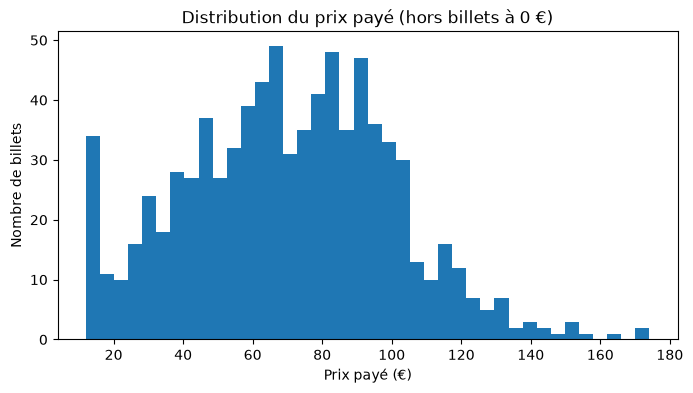

In [17]:
print("Billets entre 12 € et 15 € (12 exclu) :", ((df_billets['prix_paye_eur'] > 12) & (df_billets['prix_paye_eur'] <= 15)).sum())

plt.figure(figsize=(8, 4))
plt.hist(df_billets.loc[df_billets['prix_paye_eur'] > 0, 'prix_paye_eur'], bins=40)
plt.title("Distribution du prix payé (hors billets à 0 €)")
plt.xlabel("Prix payé (€)")
plt.ylabel("Nombre de billets")
plt.show()

La distribution du prix décroît vers la gauche puis s'empile brusquement sur 12 € (28 billets à exactement 12 €, contre ___ entre 12 et 15 €) : c'est un plancher appliqué par le système, la vraie valeur de ces 28 billets est ≤ 12 €. Décision : conserver ces billets et les signaler par un indicateur `prix_plancher` au preprocessing.

In [15]:
print("Achats le jour même (0 jour avant) :", (df_billets['achat_jours_avant'] == 0).sum())

print("\n Délais d'achat les plus longs")
display(df_billets['achat_jours_avant'].sort_values(ascending=False).head(10))

Achats le jour même (0 jour avant) : 1

 Délais d'achat les plus longs


472    187.0
611    176.0
509    175.0
584    165.0
807    164.0
489    144.0
119    138.0
254    138.0
549    137.0
7      136.0
Name: achat_jours_avant, dtype: float64

1 seul achat le jour même et des délais maximaux (jusqu'à 187 jours) qui progressent sans rupture : aucune anomalie.

## 5. Les unités

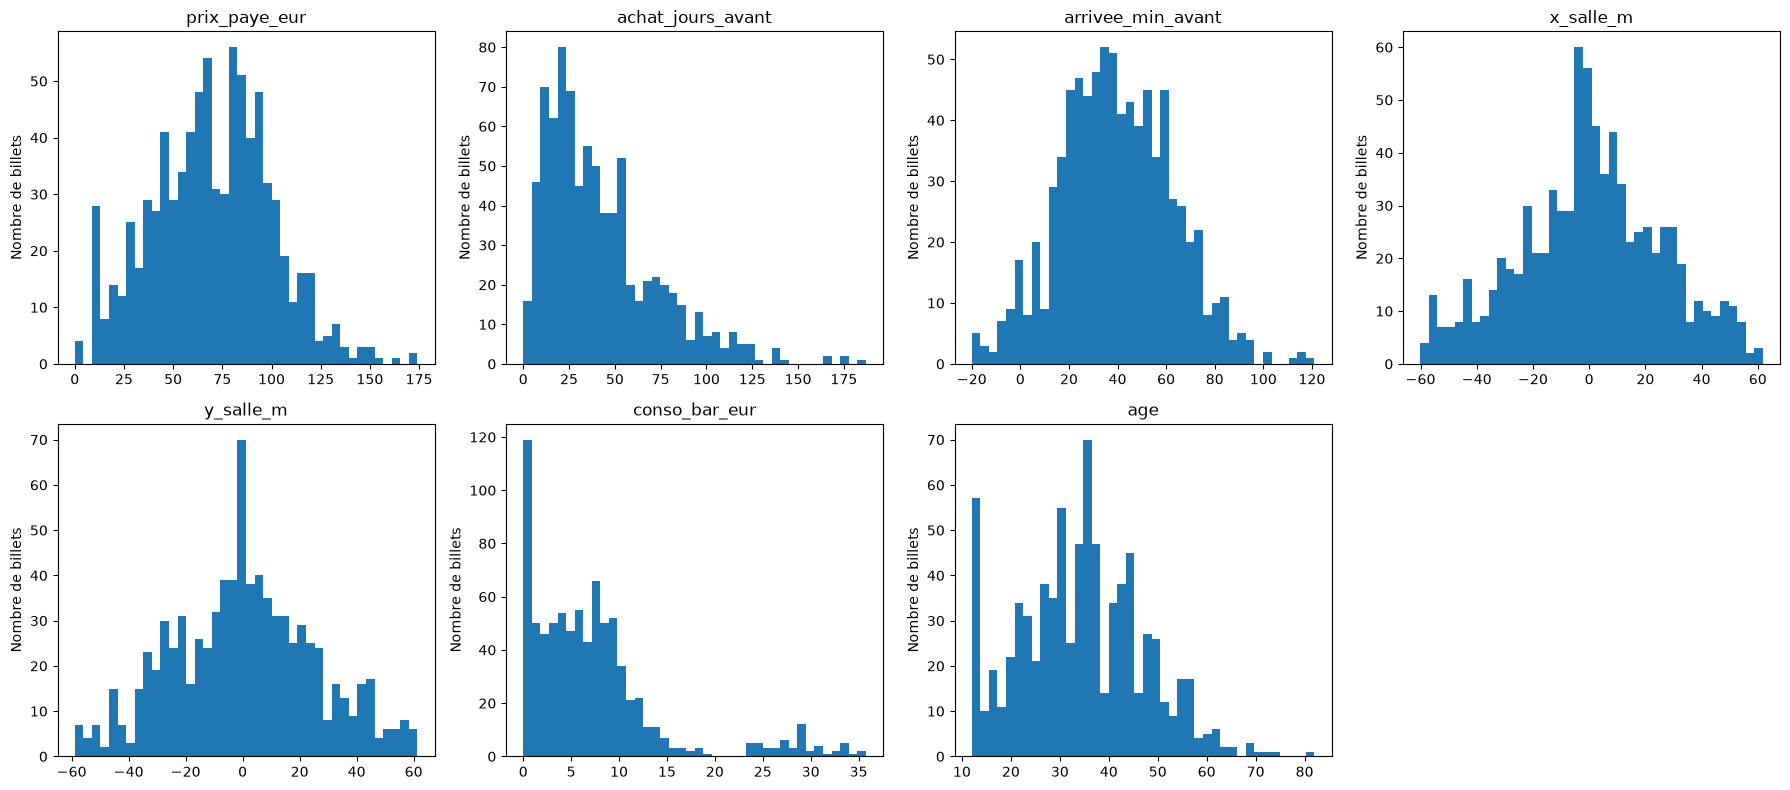

In [19]:
colonnes_num = ['prix_paye_eur', 'achat_jours_avant', 'arrivee_min_avant',
                'x_salle_m', 'y_salle_m', 'conso_bar_eur', 'age']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(colonnes_num):
    axes[i].hist(df_billets[col].dropna(), bins=40)
    axes[i].set_title(col)
    axes[i].set_ylabel("Nombre de billets")

axes[-1].axis('off')   # 7 colonnes pour 8 cases : on masque la dernière
plt.tight_layout()
plt.show()

Les ordres de grandeur sont cohérents avec les unités annoncées (euros, jours, minutes, mètres, années) ; aucune colonne ne forme de groupe décalé d'un facteur rond. Deux particularités ont été vérifiées : un second groupe de consommation entre 23 et 36 € et un pic de positions au centre de la salle.

In [21]:
# 1. Le second paquet de consommation correspond-il à une zone ?
print("Consommation au bar par zone")
display(df_billets.groupby('zone')['conso_bar_eur'].describe().round(2))

print("\n Billets consommant plus de 20 € : répartition par zone")
display(df_billets.loc[df_billets['conso_bar_eur'] > 20, 'zone'].value_counts())

# 2. Le pic au centre : position par défaut ou vraie concentration ?
masque_centre = (df_billets['x_salle_m'].abs() < 2) & (df_billets['y_salle_m'].abs() < 2)
print("\n Billets à moins de 2 m du centre :", masque_centre.sum())
print(" Billets exactement en (0, 0)     :", ((df_billets['x_salle_m'] == 0) & (df_billets['y_salle_m'] == 0)).sum())
print("\n Répartition par zone des billets proches du centre")
display(df_billets.loc[masque_centre, 'zone'].value_counts())

Consommation au bar par zone


,count,mean,std,min,25%,50%,75%,max
zone,,,,,,,,
fosse,219.0,6.03,4.14,0.00,2.62,5.90,9.34,15.23
gradin bas,286.0,5.76,4.04,0.00,2.46,5.72,8.41,17.78
gradin haut,243.0,5.19,4.06,0.00,1.56,5.17,7.97,18.40
loge,56.0,28.18,3.69,18.48,25.12,28.68,30.40,35.76



 Billets consommant plus de 20 € : répartition par zone


zone
loge    54
Name: count, dtype: int64


 Billets à moins de 2 m du centre : 32
 Billets exactement en (0, 0)     : 1

 Répartition par zone des billets proches du centre


zone
fosse    32
Name: count, dtype: int64

Le second groupe de consommation correspond entièrement à la loge (54 billets sur 54 au-delà de 20 €, consommation de 18 à 36 €, moyenne 28 € contre 5 à 6 € ailleurs) : c'est un segment réel, et la zone, connue dès l'achat, sera un prédicteur clé pour Q5 et Q6. Le pic au centre correspond à 32 billets de fosse, dont 1 seul exactement en (0, 0) : c'est une vraie concentration de spectateurs, pas une position par défaut.

In [20]:
controle = []
for col in colonnes_num:
    serie = df_billets[col].dropna()
    controle.append({
        'colonne': col,
        'min': serie.min(),
        'nb au min': (serie == serie.min()).sum(),
        'max': serie.max(),
        'nb au max': (serie == serie.max()).sum(),
        'valeurs distinctes': serie.nunique()
    })

print("Contrôle des extrémités par colonne")
display(pd.DataFrame(controle))

Contrôle des extrémités par colonne


,colonne,min,nb au min,max,nb au max,valeurs distinctes
0,prix_paye_eur,0.0,4,174.13,2,654
1,achat_jours_avant,0.0,1,187.00,1,126
2,arrivee_min_avant,-20.0,4,121.00,1,109
3,x_salle_m,-60.1,1,61.80,1,495
4,y_salle_m,-58.9,1,61.30,1,493
5,conso_bar_eur,0.0,83,35.76,1,505
6,age,12.0,48,82.00,1,59


Seuls `age` (48 billets à 12 ans), `prix_paye_eur` (4 à 0 €), `arrivee_min_avant` (4 à −20 min) et `conso_bar_eur` (83 à 0 €) s'empilent sur leur minimum, déjà traités à l'étape 4 ; aucune colonne ne s'empile sur son maximum.

## 6. Positions en salle

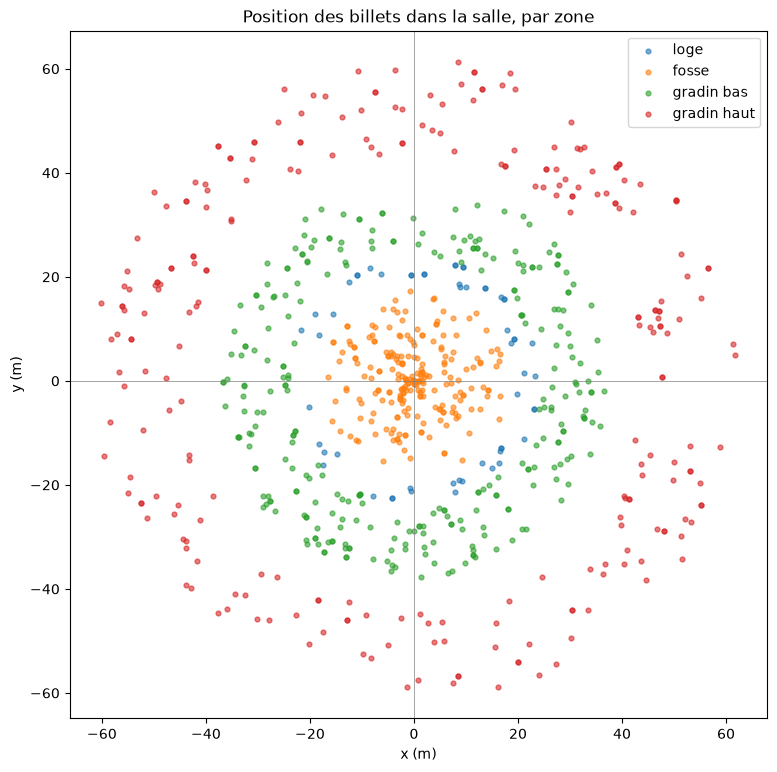

In [22]:
plt.figure(figsize=(9, 9))

for zone in df_billets['zone'].unique():
    sous_ensemble = df_billets[df_billets['zone'] == zone]
    plt.scatter(sous_ensemble['x_salle_m'], sous_ensemble['y_salle_m'], s=12, alpha=0.6, label=zone)

plt.axhline(0, color='grey', linewidth=0.5)
plt.axvline(0, color='grey', linewidth=0.5)
plt.gca().set_aspect('equal')
plt.title("Position des billets dans la salle, par zone")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.legend()
plt.show()

Les billets dessinent une salle circulaire où les zones forment des anneaux concentriques bien séparés (fosse au centre, loge, gradin bas, gradin haut) ; aucun point n'apparaît dans une zone qui n'est pas la sienne.

In [23]:
distance_centre = (df_billets['x_salle_m']**2 + df_billets['y_salle_m']**2) ** 0.5

print("Distance au centre (m) par zone")
display(distance_centre.groupby(df_billets['zone']).describe().round(1))

Distance au centre (m) par zone


,count,mean,std,min,25%,50%,75%,max
zone,,,,,,,,
fosse,224.0,8.8,5.0,0.0,4.3,8.9,12.7,18.0
gradin bas,288.0,31.1,4.1,24.0,27.6,31.3,34.8,37.9
gradin haut,252.0,52.8,5.2,44.0,47.8,53.1,57.4,62.0
loge,56.0,22.0,1.3,20.0,20.6,22.0,23.3,23.8


Chaque zone occupe une plage de distance au centre sans recouvrement avec les autres : fosse 0-18 m, loge 20-24 m, gradin bas 24-38 m, gradin haut 44-62 m. Les positions sont cohérentes avec les zones et avec une unité en mètres (diamètre ≈ 124 m) : aucune correction nécessaire.

## 7. Lien avec le DataSet des événements 

In [24]:
df_evenements = pd.read_csv('../data/raw/Dome_evenements.csv')

# Version sans les 2 doublons, pour les comparaisons (on ne modifie pas le fichier brut)
evenements_uniques = df_evenements.drop_duplicates()

print("Événements (bruts)   :", len(df_evenements))
print("Événements (uniques) :", len(evenements_uniques))

Événements (bruts)   : 98
Événements (uniques) : 96


In [25]:
ids_billets = set(df_billets['evenement_id'])
ids_evenements = set(evenements_uniques['evenement_id'])

orphelins = ids_billets - ids_evenements
sans_billet = ids_evenements - ids_billets

print("Événements présents dans les billets   :", len(ids_billets))
print("Billets pointant vers un événement absent :", df_billets['evenement_id'].isin(orphelins).sum(), "→", sorted(orphelins))
print("Événements sans aucun billet dans l'échantillon :", len(sans_billet))
print(sorted(sans_billet))

Événements présents dans les billets   : 94
Billets pointant vers un événement absent : 0 → []
Événements sans aucun billet dans l'échantillon : 2
['EV347', 'EV368']


Aucun billet ne pointe vers un événement absent du fichier des événements ; 94 des 96 événements uniques sont représentés dans l'échantillon (EV347 et EV368 n'y figurent pas, ce qui est normal pour un échantillon).

In [26]:
evenements_zero = ['EV374', 'EV303', 'EV355']

print("Billets de l'échantillon pour les événements à 0 billet vendu")
display(df_billets[df_billets['evenement_id'].isin(evenements_zero)]
        .groupby('evenement_id').size().reindex(evenements_zero, fill_value=0))

print("\n Pour comparaison : nombre moyen de billets par événement dans l'échantillon :",
      round(df_billets.groupby('evenement_id').size().mean(), 1))

Billets de l'échantillon pour les événements à 0 billet vendu


evenement_id
EV374    12
EV303     7
EV355     6
dtype: int64


 Pour comparaison : nombre moyen de billets par événement dans l'échantillon : 8.7


Les 3 événements à 0 billet vendu ont 12, 7 et 6 billets dans l'échantillon (moyenne : 8,7 par événement) : des spectateurs étaient présents, ce ne sont pas des annulations. Décision : `billets_vendus = 0` est traité comme inconnu ; ces 3 événements sont exclus des analyses de remplissage et de prévision (Q1 à Q4), leurs billets sont conservés.

Rapport prix payé moyen / prix moyen de l'événement


count    94.00
mean      1.00
std       0.15
min       0.59
25%       0.92
50%       0.97
75%       1.06
max       1.49
Name: rapport, dtype: float64


 Événements les plus éloignés de 1


,genre,prix_moyen_eur,prix_paye_moyen,rapport
evenement_id,,,,
EV317,sport,28.94,16.973333,0.59
EV382,rock,33.11,21.465000,0.65
EV302,spectacle,136.79,108.050000,0.79
EV365,humour,70.89,56.220000,0.79
EV323,concert pop,58.16,46.848333,0.81


,genre,prix_moyen_eur,prix_paye_moyen,rapport
evenement_id,,,,
EV348,sport,21.34,27.414286,1.28
EV338,sport,37.23,50.300000,1.35
EV306,concert pop,55.89,77.498000,1.39
EV344,concert pop,48.30,67.336667,1.39
EV320,rap,18.00,26.735000,1.49


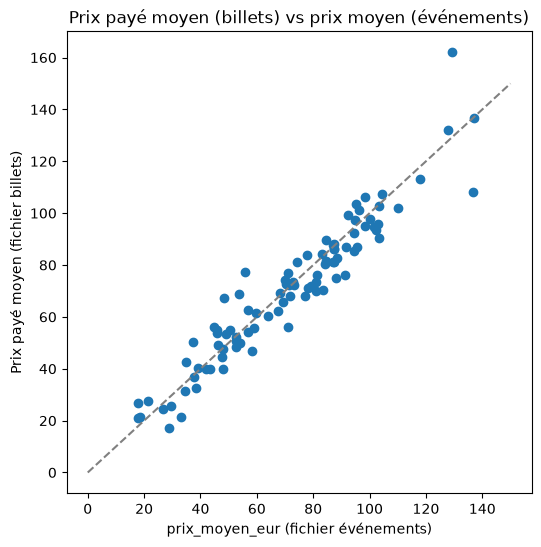

In [27]:
prix_par_evenement = df_billets[df_billets['prix_paye_eur'] > 0].groupby('evenement_id')['prix_paye_eur'].mean()

comparaison_prix = evenements_uniques.set_index('evenement_id')[['genre', 'prix_moyen_eur']].copy()
comparaison_prix['prix_paye_moyen'] = prix_par_evenement
comparaison_prix['rapport'] = (comparaison_prix['prix_paye_moyen'] / comparaison_prix['prix_moyen_eur']).round(2)
comparaison_prix = comparaison_prix.dropna()

print("Rapport prix payé moyen / prix moyen de l'événement")
display(comparaison_prix['rapport'].describe().round(2))

print("\n Événements les plus éloignés de 1")
display(comparaison_prix.sort_values('rapport').head(5))
display(comparaison_prix.sort_values('rapport').tail(5))

plt.figure(figsize=(6, 6))
plt.scatter(comparaison_prix['prix_moyen_eur'], comparaison_prix['prix_paye_moyen'])
plt.plot([0, 150], [0, 150], color='grey', linestyle='--')
plt.title("Prix payé moyen (billets) vs prix moyen (événements)")
plt.xlabel("prix_moyen_eur (fichier événements)")
plt.ylabel("Prix payé moyen (fichier billets)")
plt.show()

Le prix payé moyen par événement concorde avec `prix_moyen_eur` (rapport moyen 1,00, de 0,59 à 1,49, sans facteur rond) : aucune incohérence d'unité entre les deux fichiers ; les écarts s'expliquent par le faible nombre de billets par événement.

In [28]:
billets_par_evenement = df_billets.groupby('evenement_id').size()

couverture = evenements_uniques.set_index('evenement_id')[['billets_vendus']].copy()
couverture['billets_echantillon'] = billets_par_evenement
couverture = couverture.fillna({'billets_echantillon': 0})

print("Corrélation entre billets vendus et billets présents dans l'échantillon :",
      round(couverture['billets_vendus'].corr(couverture['billets_echantillon']), 2))
print("Part de l'échantillon dans le total vendu :",
      round(couverture['billets_echantillon'].sum() / couverture['billets_vendus'].sum() * 100, 2), "%")

Corrélation entre billets vendus et billets présents dans l'échantillon : 0.07
Part de l'échantillon dans le total vendu : 0.15 %


L'échantillon représente 0,15 % des billets vendus et n'est pas proportionnel aux ventes (corrélation 0,07) : chaque événement y pèse à peu près autant, quel que soit son remplissage. Limite à signaler pour les analyses de public (Q7), avec une pondération possible.

## 8. Récapitulatif



| Problème | Constat | Décision | Justification |
|---|---|---|---|
| Doublons | 120 lignes identiques sur 820 (≈ 15 %), chacune en double | Supprimer les copies (820 → 700) | Ne pas fausser les statistiques ni surestimer les modèles (copie en entraînement et en test) |
| Variables catégorielles | `zone` (4 modalités), `deja_venu` et `revient_saison_suivante` (oui / non) propres | Aucune | Colonnes propres |
| Information postérieure à l'achat | `revient_saison_suivante` n'est connue qu'après la saison | Exclue des variables explicatives de Q5 | Éviter une fuite de données |
| Âge manquant | 19 valeurs (14 billets uniques), réparties dans toutes les zones | Imputation par la médiane + indicateur `age_inconnu` | Conserver les billets sans créer de faux profils |
| Âge de 12 ans | 48 billets à exactement 12 ans (9 à 13 ans), consommation supérieure à celle des adultes | Traité comme inconnu, puis imputé | Valeur plancher ou par défaut, pas un âge réel |
| Consommation manquante | 16 valeurs (14 billets uniques), profil proche des consommateurs | Pas d'imputation ; billets exclus de Q5 | Un `NaN` n'est pas un 0, et c'est la cible de Q5 |
| Consommation à 0 € | 83 billets | Conserver | Valeur réelle : le spectateur n'a rien consommé |
| Prix à 0 € | 4 lignes (3 billets uniques), isolées du prix suivant (12 €) | Conserver, exclure des analyses de prix | Invitations probables |
| Prix de 12 € | 28 billets empilés sur 12 €, distribution coupée à gauche | Conserver + indicateur `prix_plancher` | Plancher du système : vraie valeur ≤ 12 € |
| Arrivées négatives | 33 lignes (30 billets uniques), retards de 1 à 20 min | Conserver | Retardataires plausibles, utiles pour Q9 |
| Délai d'achat | 0 à 187 jours, sans rupture | Aucune | Valeurs plausibles |
| Consommation en loge | 18 à 36 € (moyenne 28 €) contre 5 à 6 € ailleurs | Conserver | Segment réel, prédicteur clé pour Q5 et Q6 |
| Position dans la salle | Anneaux concentriques sans recouvrement (fosse, loge, gradin bas, gradin haut) | Aucune | Positions cohérentes avec les zones et avec des mètres |
| Lien avec les événements | 0 billet orphelin ; 94 événements sur 96 représentés | Aucune | Clé de liaison fiable |
| Événements à 0 billet vendu | EV374, EV303 et EV355 ont 12, 7 et 6 billets dans l'échantillon | `billets_vendus` → inconnu ; exclus de Q1 à Q4 | Spectateurs présents : ce ne sont pas des annulations |
| Prix payé contre prix moyen | Rapport moyen 1,00 (0,59 à 1,49) | Aucune | Les deux fichiers concordent |
| Représentativité | 0,15 % des ventes, non proportionnel aux ventes (corrélation 0,07) | Signaler ; pondération possible pour Q7 | Chaque événement pèse à peu près autant |